# Experiment 09 — Does energy/force pretraining improve NMR shielding predictions?

Five figures compare **07: from scratch**, **08: coordination-weighted training**, and **09: energy/force-pretrained, then fine-tuned** on the same **50 validation structures / 7,200 atoms**. Every model uses its saved best checkpoint. These are absolute isotropic shieldings (`trace(ms)/3`, ppm), not referenced chemical shifts or full shielding tensors.

The validation set was used for checkpoint selection and earlier experimental decisions; these are development results, not an independent final test. No test-set or training-set structures are opened by this notebook. No fitting, calibration, atom exclusion or clipping is applied. Structure and atom indices are zero-based.

Run all cells with the project's `.venv` Python. The notebook recomputes inference and exports the five figures (PNG/PDF), per-atom predictions, summary CSVs and a provenance manifest beside the notebook in `09-TensorNequIP-MSIsotropy-Validation-figures/`. Set `NEQUIP_PROJECT` if the project is elsewhere.


In [1]:
from pathlib import Path
import os,sys,json,hashlib,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import torch,yaml
from ase.io import read
from ase.neighborlist import neighbor_list
from scipy.stats import wasserstein_distance
from IPython.display import display,Markdown
from importlib.metadata import version
PROJECT=Path(os.environ.get('NEQUIP_PROJECT','/Users/louismcauliffe/code/research/NequIP_experiments'))
sys.path.insert(0,str(PROJECT))
import nmr_helpers
ARTIFACTS=Path(os.environ.get('NMR09_OUTPUT_DIR',str(PROJECT/'experiments/09-TensorNequIP-MSIsotropy-Validation-figures')))
ARTIFACTS.mkdir(parents=True,exist_ok=True)
RUNS={'07':'TensorNequIP-NMR-9065266','08':'TensorNequIP-NMR-Coord3x-9083627','09':'TensorNequIP-NMR-FineTune-9086968'}
LABELS={'07':'07 · From scratch','08':'08 · Defect-weighted','09':'09 · Fine-tuned'}
COLORS={'07':'#78838D','08':'#D58D30','09':'#126EAB'}
ELEMENTS=['Si','O']
torch.set_num_threads(2)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.labelsize':11,'legend.frameon':False,'savefig.facecolor':'white'})
def sha256(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def same_state(a,b):
    if a.keys()!=b.keys():return False
    return all(torch.equal(a[k],b[k]) if torch.is_tensor(a[k]) else a[k]==b[k] for k in a)
def finish(fig,name):
    fig.savefig(ARTIFACTS/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(ARTIFACTS/(name+'.pdf'),bbox_inches='tight')
    plt.show()
print('Target: absolute isotropic shielding, trace(ms)/3, in ppm. Validation only.')


Target: absolute isotropic shielding, trace(ms)/3, in ppm. Validation only.


## Audit and fresh validation inference

Verify labels, model/checkpoint equality, input isolation and agreement with saved validation loss. Coordination means unlike Si–O neighbours within 2.2 Å with periodic boundaries; this geometric definition is cutoff dependent.

In [2]:
from graph_pes.atomic_graph import AtomicGraph
valid_path=PROJECT/'data/nmr_iso/valid.xyz'
frames=read(valid_path,index=':',format='extxyz')
assert len(frames)==50 and sum(map(len,frames))==7200
geometry=[]
for i,a in enumerate(frames):
    reference=np.asarray(a.arrays['MS_Iso_QM'],dtype=float)
    np.testing.assert_allclose(reference,np.trace(a.arrays['ms'].reshape(-1,3,3),axis1=1,axis2=2)/3,atol=1e-6)
    fields={}
    for cutoff in [2.1,2.2,2.3]:
        ii,jj=neighbor_list('ij',a,cutoff)
        unlike=((a.numbers[ii]==14)&(a.numbers[jj]==8))|((a.numbers[ii]==8)&(a.numbers[jj]==14))
        fields[f'CN_{cutoff:.1f}']=np.bincount(ii[unlike],minlength=len(a))
    geometry.append(pd.DataFrame({'structure':i,'atom':np.arange(len(a)),'element':a.get_chemical_symbols(),'reference':reference,**fields}))
geometry=pd.concat(geometry,ignore_index=True)
geometry['coordination']=geometry['CN_2.2']
geometry['defect']=geometry.coordination.ne(geometry.element.map({'Si':4,'O':2}))
geometry['category']=geometry.element+geometry.coordination.astype(str)
records=[];predictions=[]
for run,name in RUNS.items():
    folder=PROJECT/'graph-pes-results'/name
    config=yaml.safe_load((folder/'train-config.yaml').read_text())
    assert config['data'].get('test') is None
    assert Path(config['data']['valid']['path']).as_posix()=='data/nmr_iso/valid.xyz'
    assert config['data']['valid']['property_map']=={'MS_Iso_QM':'tensor'}
    model=torch.load(folder/'model.pt',map_location='cpu',weights_only=False)
    ckpt=torch.load(folder/'checkpoints/best.ckpt',map_location='cpu',weights_only=False)
    state={k.removeprefix('model.'):v for k,v in ckpt['state_dict'].items() if k.startswith('model.')}
    assert same_state(model.state_dict(),state),f'{run}: model.pt and best.ckpt differ'
    model.eval().requires_grad_(False)
    started=time.perf_counter();values=[]
    for a in frames:
        g=AtomicGraph.from_ase(a,cutoff=float(model.cutoff))
        assert not g.properties and not g.other
        with torch.no_grad():y=model.predict(g,['tensor'])['tensor'].cpu().numpy().copy()
        assert y.shape==(len(a),) and np.isfinite(y).all()
        values.append(y)
    assert same_state(model.state_dict(),state)
    result=geometry.copy();result['run']=run;result['prediction']=np.concatenate(values)
    result['error']=result.prediction-result.reference;result['AE']=result.error.abs()
    predictions.append(result)
    saved=yaml.safe_load((folder/'summary.yaml').read_text())['early_stopping/best_valid_loss']/1000
    assert np.isclose(np.mean(result.error**2),saved,rtol=.005)
    records.append({'run':run,'name':name,'best_epoch_1based':int(ckpt['epoch'])+1,'model_sha256':sha256(folder/'model.pt'),'checkpoint_sha256':sha256(folder/'checkpoints/best.ckpt'),'config_sha256':sha256(folder/'train-config.yaml'),'saved_valid_MSE':saved})
    print(f'{run}: all 50 validation structures evaluated in {time.perf_counter()-started:.1f}s; best checkpoint verified.',flush=True)
    del model,ckpt,state
sites=pd.concat(predictions,ignore_index=True)
provenance=pd.DataFrame(records)
assert len(sites)==21600
sites.to_csv(ARTIFACTS/'validation-sites.csv',index=False)
provenance.to_csv(ARTIFACTS/'provenance.csv',index=False)
display(provenance[['run','best_epoch_1based','saved_valid_MSE']].round(4))
print('Coordination counts (Si–O neighbours within 2.2 Å, periodic):')
display(geometry.groupby('category',sort=False).agg(sites=('atom','size'),structures=('structure','nunique')))


07: all 50 validation structures evaluated in 15.5s; best checkpoint verified.
08: all 50 validation structures evaluated in 15.6s; best checkpoint verified.
09: all 50 validation structures evaluated in 15.2s; best checkpoint verified.
Coordination counts (Si–O neighbours within 2.2 Å, periodic):


,run,best_epoch_1based,saved_valid_MSE
0,07,188,3.7311
1,08,287,3.4097
2,09,295,3.1689


,sites,structures
category,,
O2,4762,50
Si4,2386,50
O3,26,13
O1,12,10
Si5,14,5


## Statistics used in the figures

All errors are unweighted. Bootstrap intervals resample whole structures 4,000 times (seed 42), pairing models within each resample. Correlated structures can make these intervals too narrow; one run per recipe does not measure seed variability.

In [3]:
def score(g):
    e=g.error.to_numpy();a=np.abs(e)
    return {'N':len(g),'MAE':a.mean(),'RMSE':np.sqrt(np.mean(e**2)),'bias':e.mean(),'p95':np.quantile(a,.95),'p99':np.quantile(a,.99),'max':a.max(),'above5':int((a>5).sum()),'above10':int((a>10).sum())}
metrics=pd.DataFrame([{'run':r,'element':el,**score(g)} for (r,el),g in sites.groupby(['run','element'])])
structure_metrics=pd.DataFrame([{'run':r,'element':el,'structure':s,**score(g)} for (r,el,s),g in sites.groupby(['run','element','structure'])])
coord_metrics=pd.DataFrame([{'run':r,'element':el,'category':cat,'structures':g.structure.nunique(),**score(g)} for (r,el,cat),g in sites.groupby(['run','element','category'])])
# Paired structure bootstrap: resample the same 50 structures for every model.
# Atoms from one structure are not independent bootstrap units.
rng=np.random.default_rng(42);draws=rng.integers(0,50,size=(4000,50))
boot={};intervals=[];comparisons=[]
for el in ELEMENTS:
    for run in RUNS:
        g=sites[(sites.run==run)&(sites.element==el)]
        agg=g.assign(SE=g.error**2).groupby('structure').agg(N=('AE','size'),SAE=('AE','sum'),SSE=('SE','sum')).reindex(range(50))
        denom=agg.N.to_numpy()[draws].sum(axis=1)
        boot[(run,el,'MAE')]=agg.SAE.to_numpy()[draws].sum(axis=1)/denom
        boot[(run,el,'RMSE')]=np.sqrt(agg.SSE.to_numpy()[draws].sum(axis=1)/denom)
        for metric in ['MAE','RMSE']:
            lo,hi=np.quantile(boot[(run,el,metric)],[.025,.975])
            intervals.append({'run':run,'element':el,'metric':metric,'lo':lo,'hi':hi})
    for baseline in ['07','08']:
        for metric in ['MAE','RMSE']:
            old=metrics.query('run==@baseline and element==@el')[metric].iloc[0]
            new=metrics.query('run=="09" and element==@el')[metric].iloc[0]
            delta=boot[('09',el,metric)]-boot[(baseline,el,metric)]
            lo,hi=np.quantile(delta,[.025,.975])
            comparisons.append({'baseline':baseline,'element':el,'metric':metric,'old':old,'new':new,'reduction_pct':100*(old-new)/old,'delta_ppm':new-old,'delta_lo':lo,'delta_hi':hi})
intervals=pd.DataFrame(intervals);comparisons=pd.DataFrame(comparisons)
spectral=pd.DataFrame([{'run':run,'element':el,'W1_ppm':wasserstein_distance(g.reference,g.prediction),'mean_shift_ppm':g.prediction.mean()-g.reference.mean(),'SD_ratio':g.prediction.std(ddof=0)/g.reference.std(ddof=0)} for (run,el),g in sites.groupby(['run','element'])])
concentration=[]
for (run,el),g in sites.groupby(['run','element']):
    sq=g.error**2;k=int(np.ceil(.01*len(g)))
    concentration.append({'run':run,'element':el,'defect_sites':int(g.defect.sum()),'defect_SSE_pct':100*sq[g.defect].sum()/sq.sum(),'top1pct_sites':k,'top1pct_SSE_pct':100*sq.nlargest(k).sum()/sq.sum()})
concentration=pd.DataFrame(concentration)
worst=pd.concat([g.nlargest(5,'AE') for el,g in sites[sites.run=='09'].groupby('element')])
for name in ['metrics','structure_metrics','coord_metrics','comparisons','intervals','spectral','concentration','worst']:
    globals()[name].to_csv(ARTIFACTS/(name+'.csv'),index=False)
display(metrics.round(3))
print('Paired changes: negative delta favours fine-tuning. Intervals assume independent structures.')
display(comparisons.round(3))


Paired changes: negative delta favours fine-tuning. Intervals assume independent structures.


,run,element,N,MAE,RMSE,bias,p95,p99,max,above5,above10
0,07,O,4800,1.071,2.235,0.131,3.517,9.331,42.041,135,43
1,07,Si,2400,0.538,1.097,-0.058,1.608,4.245,16.139,17,5
2,08,O,4800,1.048,2.149,0.013,3.203,8.833,34.124,122,41
3,08,Si,2400,0.529,0.997,0.022,1.596,4.105,12.946,14,3
4,09,O,4800,0.957,2.093,0.101,2.843,8.815,45.822,114,42
5,09,Si,2400,0.486,0.862,0.087,1.433,3.654,9.871,13,0


,baseline,element,metric,old,new,reduction_pct,delta_ppm,delta_lo,delta_hi
0,07,Si,MAE,0.538,0.486,9.673,-0.052,-0.099,-0.013
1,07,Si,RMSE,1.097,0.862,21.411,-0.235,-0.429,-0.030
2,08,Si,MAE,0.529,0.486,8.253,-0.044,-0.084,-0.013
3,08,Si,RMSE,0.997,0.862,13.516,-0.135,-0.261,-0.023
4,07,O,MAE,1.071,0.957,10.696,-0.115,-0.190,-0.049
5,07,O,RMSE,2.235,2.093,6.351,-0.142,-0.397,0.060
6,08,O,MAE,1.048,0.957,8.757,-0.092,-0.145,-0.041
7,08,O,RMSE,2.149,2.093,2.602,-0.056,-0.306,0.150


## Figure 1 — Does fine-tuning improve typical error and overall accuracy?

MAE describes the typical absolute miss; RMSE gives more weight to large misses. Each dot is the full validation estimate and each line is its 95% structure-bootstrap interval. The printed percentages compare experiment 09 with 07. Use the **paired difference intervals** in the table above to judge the comparison, rather than overlap of separate intervals.


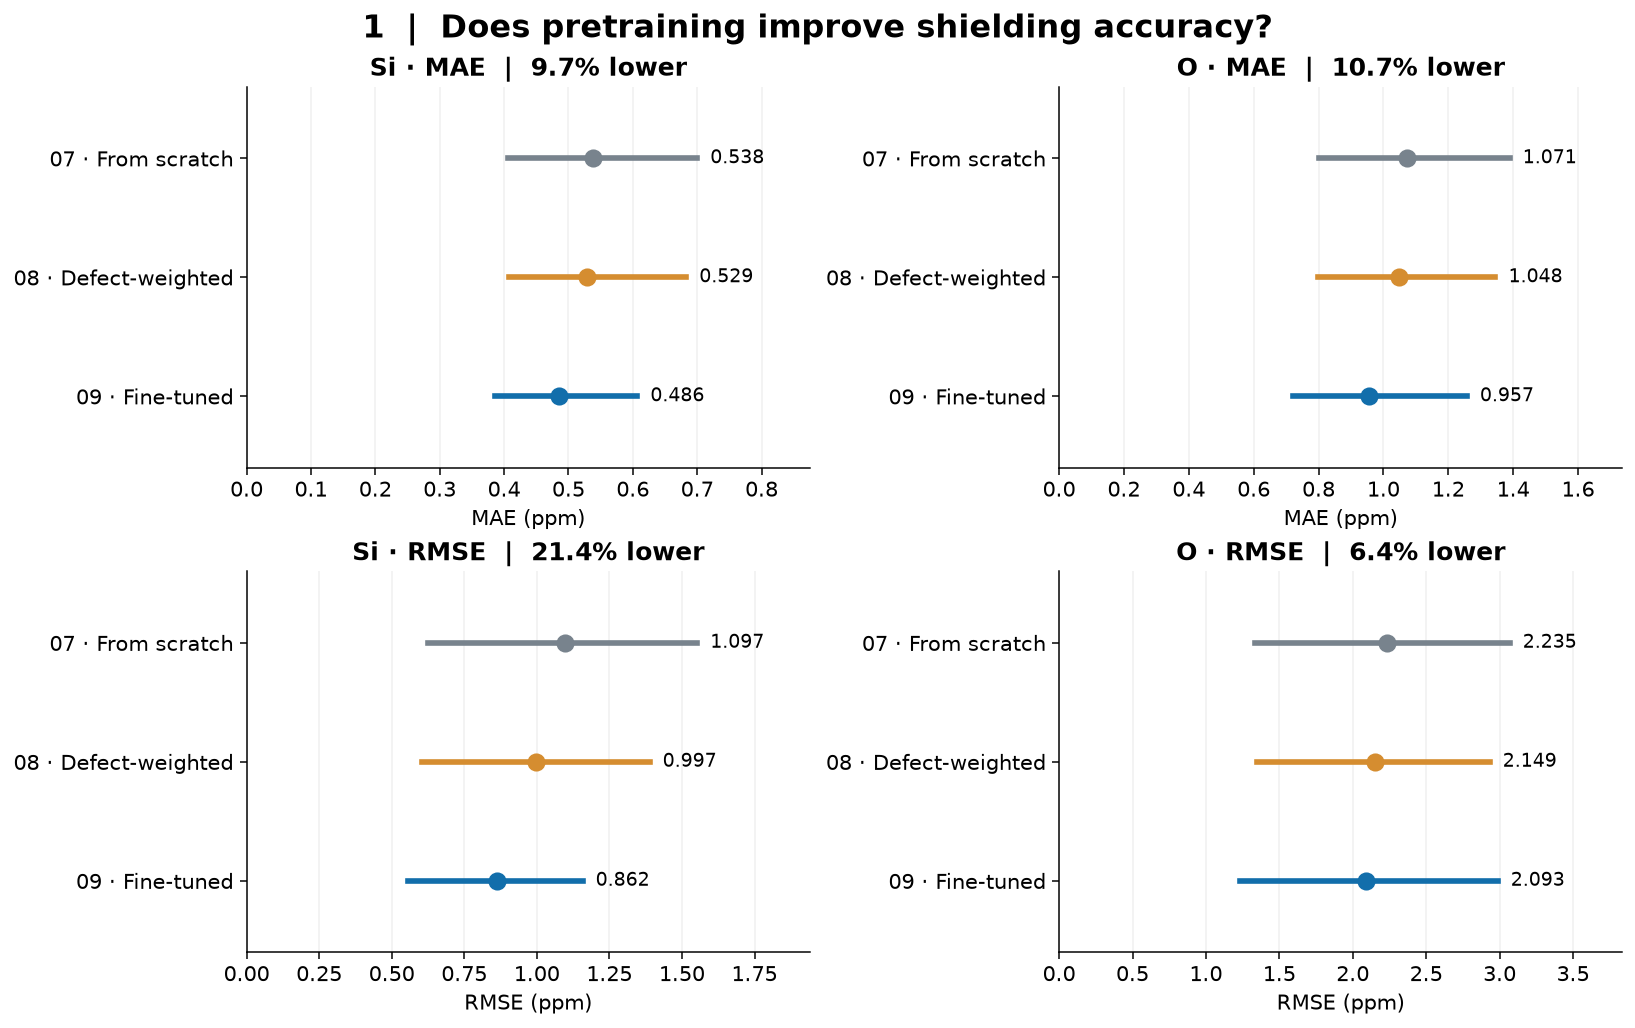

**Si:** MAE 0.538 → 0.486 ppm; paired Δ -0.052 ppm (95% interval -0.099 to -0.013); RMSE 1.097 → 0.862 ppm; paired Δ -0.235 ppm (95% interval -0.429 to -0.030).

**O:** MAE 1.071 → 0.957 ppm; paired Δ -0.115 ppm (95% interval -0.190 to -0.049); RMSE 2.235 → 2.093 ppm; paired Δ -0.142 ppm (95% interval -0.397 to +0.060).

In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,7.5),layout='constrained')
for col,el in enumerate(ELEMENTS):
 for row,metric in enumerate(['MAE','RMSE']):
  ax=axes[row,col]
  for j,run in enumerate(RUNS):
   value=metrics.query('run==@run and element==@el')[metric].iloc[0]
   ci=intervals.query('run==@run and element==@el and metric==@metric').iloc[0]
   ax.plot([ci.lo,ci.hi],[j,j],color=COLORS[run],lw=3)
   ax.scatter(value,j,s=75,color=COLORS[run],zorder=3)
   ax.annotate(f'{value:.3f}',(ci.hi,j),xytext=(7,0),textcoords='offset points',va='center',fontsize=10)
  change=comparisons.query('baseline=="07" and element==@el and metric==@metric').iloc[0]
  ax.set(title=f'{el} · {metric}  |  {abs(change.reduction_pct):.1f}% '+('lower' if change.reduction_pct>=0 else 'higher'),xlabel=f'{metric} (ppm)',yticks=range(3),yticklabels=[LABELS[r] for r in RUNS],ylim=(2.6,-.6))
  right=intervals.query('element==@el and metric==@metric').hi.max()
  ax.set_xlim(0,right*1.25);ax.grid(axis='x',alpha=.2)
fig.suptitle('1  |  Does pretraining improve shielding accuracy?',fontsize=17,fontweight='bold')
finish(fig,'01-overall-accuracy')
for el in ELEMENTS:
 g=comparisons.query('baseline=="07" and element==@el')
 display(Markdown('**'+el+':** '+ '; '.join(f'{r.metric} {r.old:.3f} → {r.new:.3f} ppm; paired Δ {r.delta_ppm:+.3f} ppm (95% interval {r.delta_lo:+.3f} to {r.delta_hi:+.3f})' for r in g.itertuples())+'.'))


**Takeaway:** 09 gives the lowest MAE and RMSE point estimates for both elements. Against 07, MAE falls **9.7% for Si** and **10.7% for O**. The paired 95% interval supports lower MAE for both, and lower Si RMSE. For O RMSE, however, the paired interval is **−0.397 to +0.060 ppm**: the 6.4% point-estimate reduction is not resolved confidently by this 50-structure bootstrap. The same qualification applies to O RMSE versus 08. These intervals describe this validation cohort, not variability between training seeds.


## Figure 2 — What does the new model get right, and where does it miss?

One point per atom for experiment 09; the dashed line is perfect prediction. Orange points have nonstandard coordination under the 2.2 Å definition, while blue points have Si4/O2 coordination. Every atom is plotted with equal x/y scales and no clipping. The two largest absolute errors per element are labelled `structure:atom` (zero-based); those labels locate an atom, not its coordination.

The metric box reports unweighted validation MAE and RMSE in ppm and $R^2 = 1-\sum_i(\hat{y}_i-y_i)^2/\sum_i(y_i-\bar{y})^2$, calculated separately for each element over all its validation atoms.


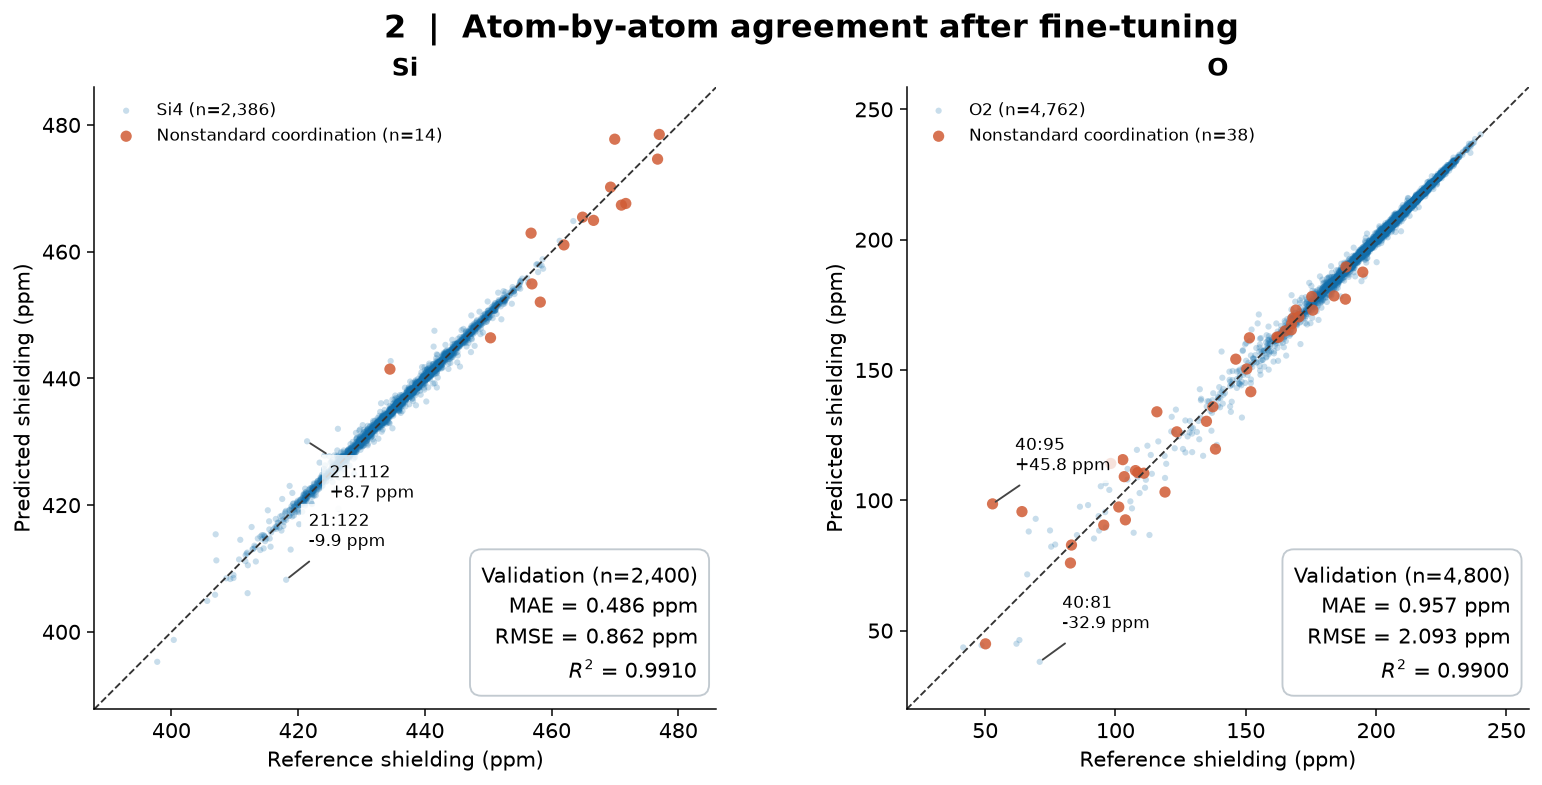

,element,structure,atom,category,reference,prediction,error
0,O,40,95,O1,52.829,98.651,45.822
1,O,40,81,O2,70.920,38.045,-32.874
2,O,40,17,O1,64.117,95.690,31.572
3,O,40,92,O2,113.039,86.717,-26.322
4,O,40,72,O2,69.381,92.923,23.542
5,Si,21,122,Si4,418.103,408.232,-9.871
6,Si,21,112,Si4,421.406,430.089,8.683
7,Si,40,142,Si4,406.979,415.406,8.427
8,Si,40,136,Si4,434.600,442.750,8.151
9,Si,40,107,Si5,469.963,477.764,7.801


In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,5.7),layout='constrained')
for ax,el in zip(axes,ELEMENTS):
 g=sites.query('run=="09" and element==@el')
 for mask,color,label,size,alpha in [(~g.defect,COLORS['09'],('Si4' if el=='Si' else 'O2'),11,.23),(g.defect,'#D05C35','Nonstandard coordination',36,.85)]:
  sub=g[mask];ax.scatter(sub.reference,sub.prediction,s=size,c=color,alpha=alpha,label=f'{label} (n={len(sub):,})',rasterized=True,edgecolors='none')
 lo=min(g.reference.min(),g.prediction.min());hi=max(g.reference.max(),g.prediction.max());pad=(hi-lo)*.09
 ax.plot([lo-pad,hi+pad],[lo-pad,hi+pad],'--',color='#333333',lw=1)
 for j,r in enumerate(g.nlargest(2,'AE').itertuples()):
  ax.annotate(f'{r.structure}:{r.atom}\n{r.error:+.1f} ppm',(r.reference,r.prediction),xytext=(12,18 if j==0 or el=='O' else -30),textcoords='offset points',fontsize=9,arrowprops={'arrowstyle':'-','color':'#444444'},bbox={'facecolor':'white','edgecolor':'none','alpha':.8})
 ax.set(xlim=(lo-pad,hi+pad),ylim=(lo-pad,hi+pad),xlabel='Reference shielding (ppm)',ylabel='Predicted shielding (ppm)',title=el)
 ax.set_aspect('equal',adjustable='box');ax.legend(loc='upper left',fontsize=9)
 # Validation metrics use every atom of this element, including outliers.
 errors=g.error.to_numpy(dtype=np.float64)
 reference=g.reference.to_numpy(dtype=np.float64)
 mae=np.mean(np.abs(errors))
 rmse=np.sqrt(np.mean(errors**2))
 sst=np.sum((reference-reference.mean())**2)
 r_squared=1-np.sum(errors**2)/sst if sst>0 else np.nan
 metric_label=f"Validation (n={len(g):,})\nMAE = {mae:.3f} ppm\nRMSE = {rmse:.3f} ppm\n$R^2$ = {r_squared:.4f}"
 ax.text(.97,.04,metric_label,transform=ax.transAxes,ha='right',va='bottom',fontsize=11,
         linespacing=1.5,bbox=dict(boxstyle='round,pad=0.55',facecolor='white',edgecolor='#BFC7CE',alpha=.95))
fig.suptitle('2  |  Atom-by-atom agreement after fine-tuning',fontsize=17,fontweight='bold')
finish(fig,'02-finetuned-parity')
display(worst[['element','structure','atom','category','reference','prediction','error']].round(3))


**Takeaway:** the worst O residual is **+45.82 ppm at structure 40, atom 95 (O1)**, but the second largest is **−32.87 ppm at structure 40, atom 81 (O2)**. The largest Si residual is at a **Si4** site (structure 21, atom 122). Nonstandard coordination identifies some difficult sites, but standard coordination does not guarantee an accurate prediction. Structure 40 means the 41st structure in the file, not index 41.


## Figure 3 — Does the predicted shielding distribution retain the reference shape?

Each curve sums equal-weight Gaussian peaks at all atomic shieldings and is normalised to area one. A common illustrative width **σ = 1 ppm (FWHM ≈ 2.35 ppm)** is used for every curve and both elements; no peak alignment or bias correction is applied. This visualises the isotropic shielding distribution, **not a simulated experimental NMR spectrum**: it omits referencing, tensor anisotropy, quadrupolar effects, acquisition physics and physical linewidths. Validation structures receive equal weight here because each has the same composition and atom count.

Wasserstein distance W₁ is computed from the **unbroadened** reference/predicted values: it measures average displacement between distributions in ppm. Matching a distribution alone does not guarantee the correct shielding for each atom.


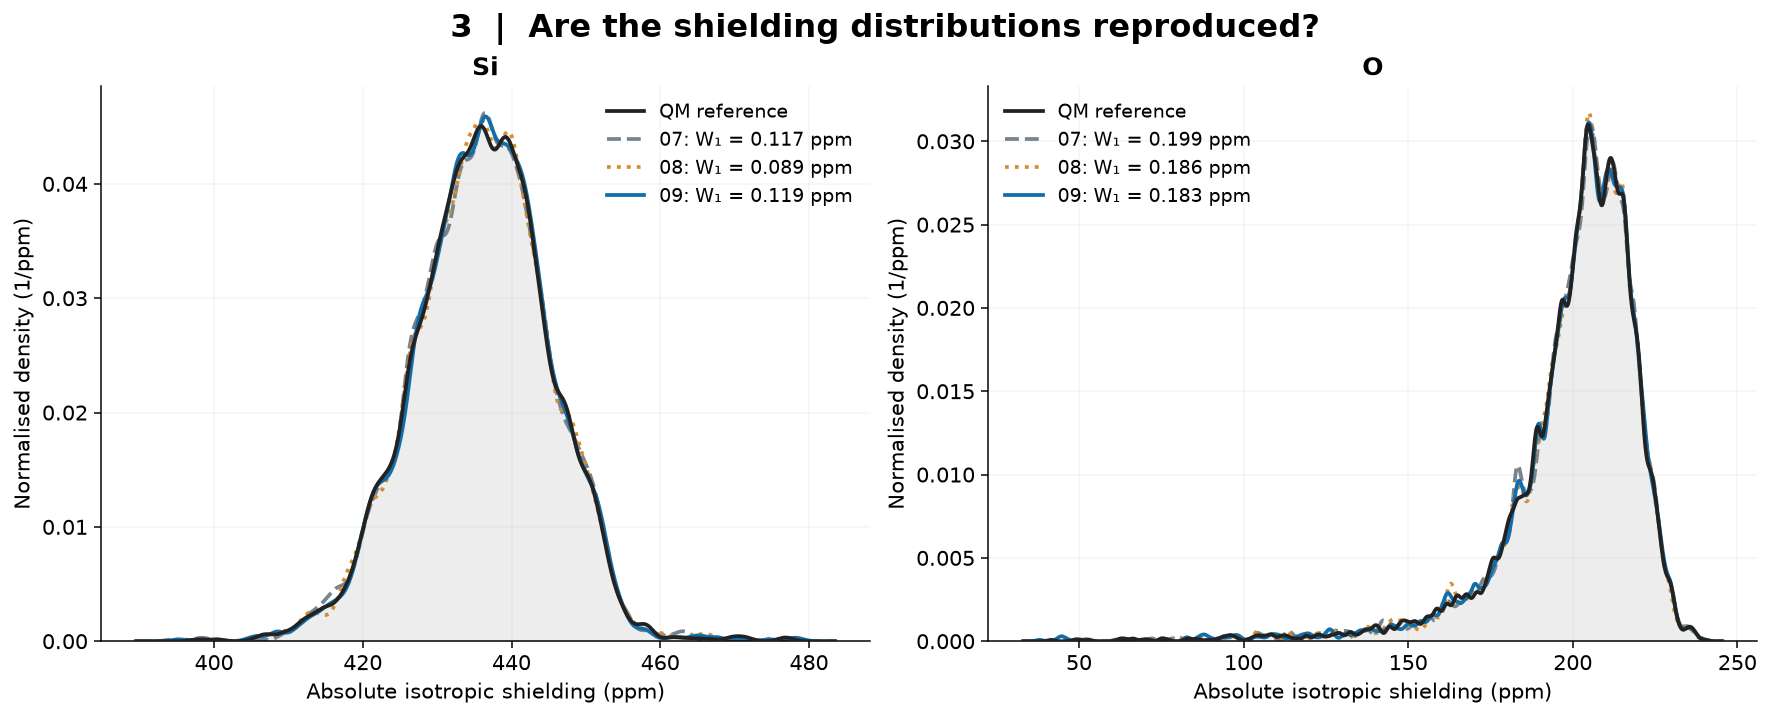

,run,element,W1_ppm,mean_shift_ppm,SD_ratio
0,07,O,0.1993,0.1312,0.9871
1,07,Si,0.1175,-0.0580,0.9974
2,08,O,0.1862,0.0128,0.9835
3,08,Si,0.0886,0.0224,0.9985
4,09,O,0.1830,0.1008,1.0002
5,09,Si,0.1188,0.0867,0.9984


In [6]:
SIGMA=1.0
fig,axes=plt.subplots(1,2,figsize=(13,5.2),layout='constrained')
def density(values,grid):
 result=np.zeros_like(grid)
 for chunk in np.array_split(np.asarray(values),max(1,int(np.ceil(len(values)/500)))):
  result+=np.exp(-.5*((grid[:,None]-chunk[None,:])/SIGMA)**2).sum(axis=1)
 return result/(len(values)*SIGMA*np.sqrt(2*np.pi))
for ax,el in zip(axes,ELEMENTS):
 g=sites.query('element==@el');ref=geometry.query('element==@el').reference.to_numpy()
 grid=np.linspace(min(g.reference.min(),g.prediction.min())-5*SIGMA,max(g.reference.max(),g.prediction.max())+5*SIGMA,1400)
 ax.fill_between(grid,density(ref,grid),color='#222222',alpha=.08)
 ax.plot(grid,density(ref,grid),color='#222222',lw=2,label='QM reference',zorder=5)
 for run,ls in zip(RUNS,['--',':','-']):
  values=g[g.run==run].prediction.to_numpy();w=spectral.query('run==@run and element==@el').W1_ppm.iloc[0]
  ax.plot(grid,density(values,grid),color=COLORS[run],ls=ls,lw=2,label=f'{run}: W₁ = {w:.3f} ppm')
 ax.set(title=el,xlabel='Absolute isotropic shielding (ppm)',ylabel='Normalised density (1/ppm)',ylim=(0,None))
 ax.legend(fontsize=10);ax.grid(alpha=.12)
fig.suptitle('3  |  Are the shielding distributions reproduced?',fontsize=17,fontweight='bold')
finish(fig,'03-shielding-distributions')
display(spectral.round(4))


**Takeaway:** all three models already reproduce the dominant distribution shapes closely at the illustrative 1 ppm broadening. Fine-tuning reduces O W₁ from **0.199 to 0.183 ppm**, but Si W₁ is **0.119 ppm versus 0.117 for 07 and 0.089 for 08**. Thus 09's better atom-level accuracy does **not** give uniformly better distribution agreement. These small differences have not been assigned uncertainty intervals, and the curves are not experimental spectra.


## Figure 4 — Are the large errors actually going away?

The curves show the fraction of atoms with absolute error at least as large as the x-axis value; lower is better. The log percentage axis makes the rare tail visible. Curves extend to each model's largest error, with no discarded outliers. The accompanying table counts errors above 5 and 10 ppm and quantifies how much total squared error comes from the worst 1% of sites and from nonstandard coordination sites. The thresholds are descriptive, not asserted NMR accuracy requirements.


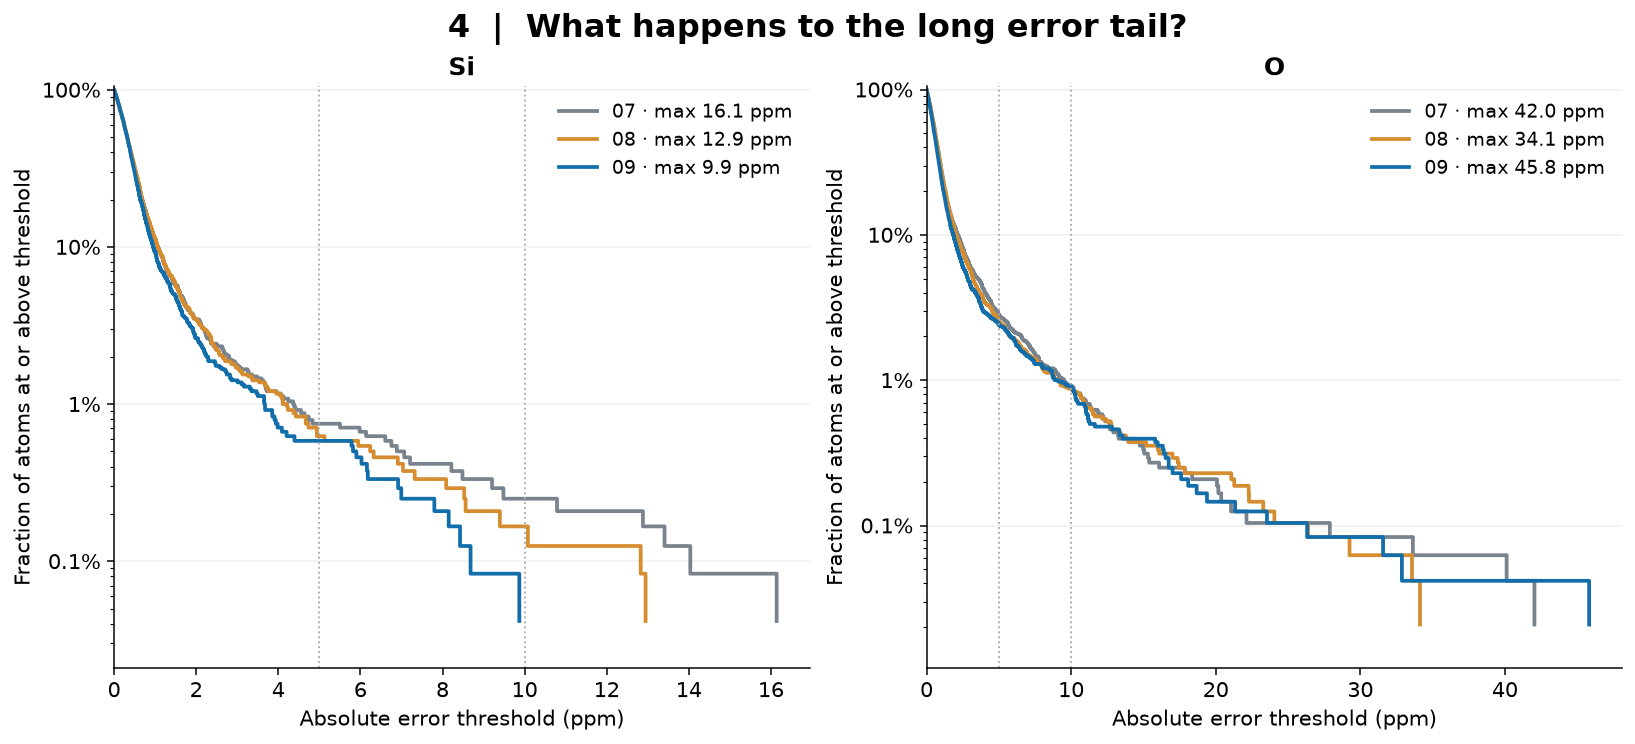

,run,element,N,p95,p99,max,above5,above10,defect_sites,defect_SSE_pct,top1pct_sites,top1pct_SSE_pct
0,07,O,4800,3.517,9.331,42.041,135,43,38,24.975,48,56.341
1,07,Si,2400,1.608,4.245,16.139,17,5,14,35.439,24,59.648
2,08,O,4800,3.203,8.833,34.124,122,41,38,19.724,48,57.440
3,08,Si,2400,1.596,4.105,12.946,14,3,14,27.781,24,51.641
4,09,O,4800,2.843,8.815,45.822,114,42,38,25.190,48,61.553
5,09,Si,2400,1.433,3.654,9.871,13,0,14,13.835,24,47.835


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,5.4),layout='constrained')
for ax,el in zip(axes,ELEMENTS):
 for run in RUNS:
  a=np.sort(sites.query('run==@run and element==@el').AE.to_numpy())
  ax.step(a,np.arange(len(a),0,-1)/len(a),where='post',color=COLORS[run],lw=2,label=f'{run} · max {a[-1]:.1f} ppm')
 ax.set_yscale('log');ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,pos:f'{100*x:g}%'))
 ax.set(xlabel='Absolute error threshold (ppm)',ylabel='Fraction of atoms at or above threshold',title=el,xlim=(0,None),ylim=(.5/len(a),1.05))
 for threshold in [5,10]:ax.axvline(threshold,color='#AAAAAA',ls=':',lw=1)
 ax.grid(axis='y',which='major',alpha=.2);ax.legend(fontsize=10)
fig.suptitle('4  |  What happens to the long error tail?',fontsize=17,fontweight='bold')
finish(fig,'04-error-tails')
tail=metrics[['run','element','N','p95','p99','max','above5','above10']].merge(concentration,on=['run','element'])
display(tail.round(3))


**Takeaway:** Si's maximum error falls **16.14 → 9.87 ppm**, and its count above 10 ppm falls **5 → 0** relative to 07. Oxygen's count above 10 ppm barely changes (**43 → 42**), while its maximum rises **42.04 → 45.82 ppm**. For 09, the worst 1% of O sites contribute **61.6%** of total O squared error. Nonstandard O sites account for **25.2%** of that total, so **74.8% remains on O2 sites**; a small defect-only analysis would miss most of the aggregate O error.


## Figure 5 — Who benefits: most structures, or only selected environments?

**Top:** each point is one validation structure; below the diagonal means experiment 09 beats 07. The axes use the same range, and the largest baseline-error structure is labelled. **Bottom:** unweighted MAE within coordination groups for all three models. Labels give **atoms / distinct structures** in each group, so the small rare-site cohorts cannot be mistaken for equally strong evidence. Coordination is a descriptive association, not proof of what causes an error.


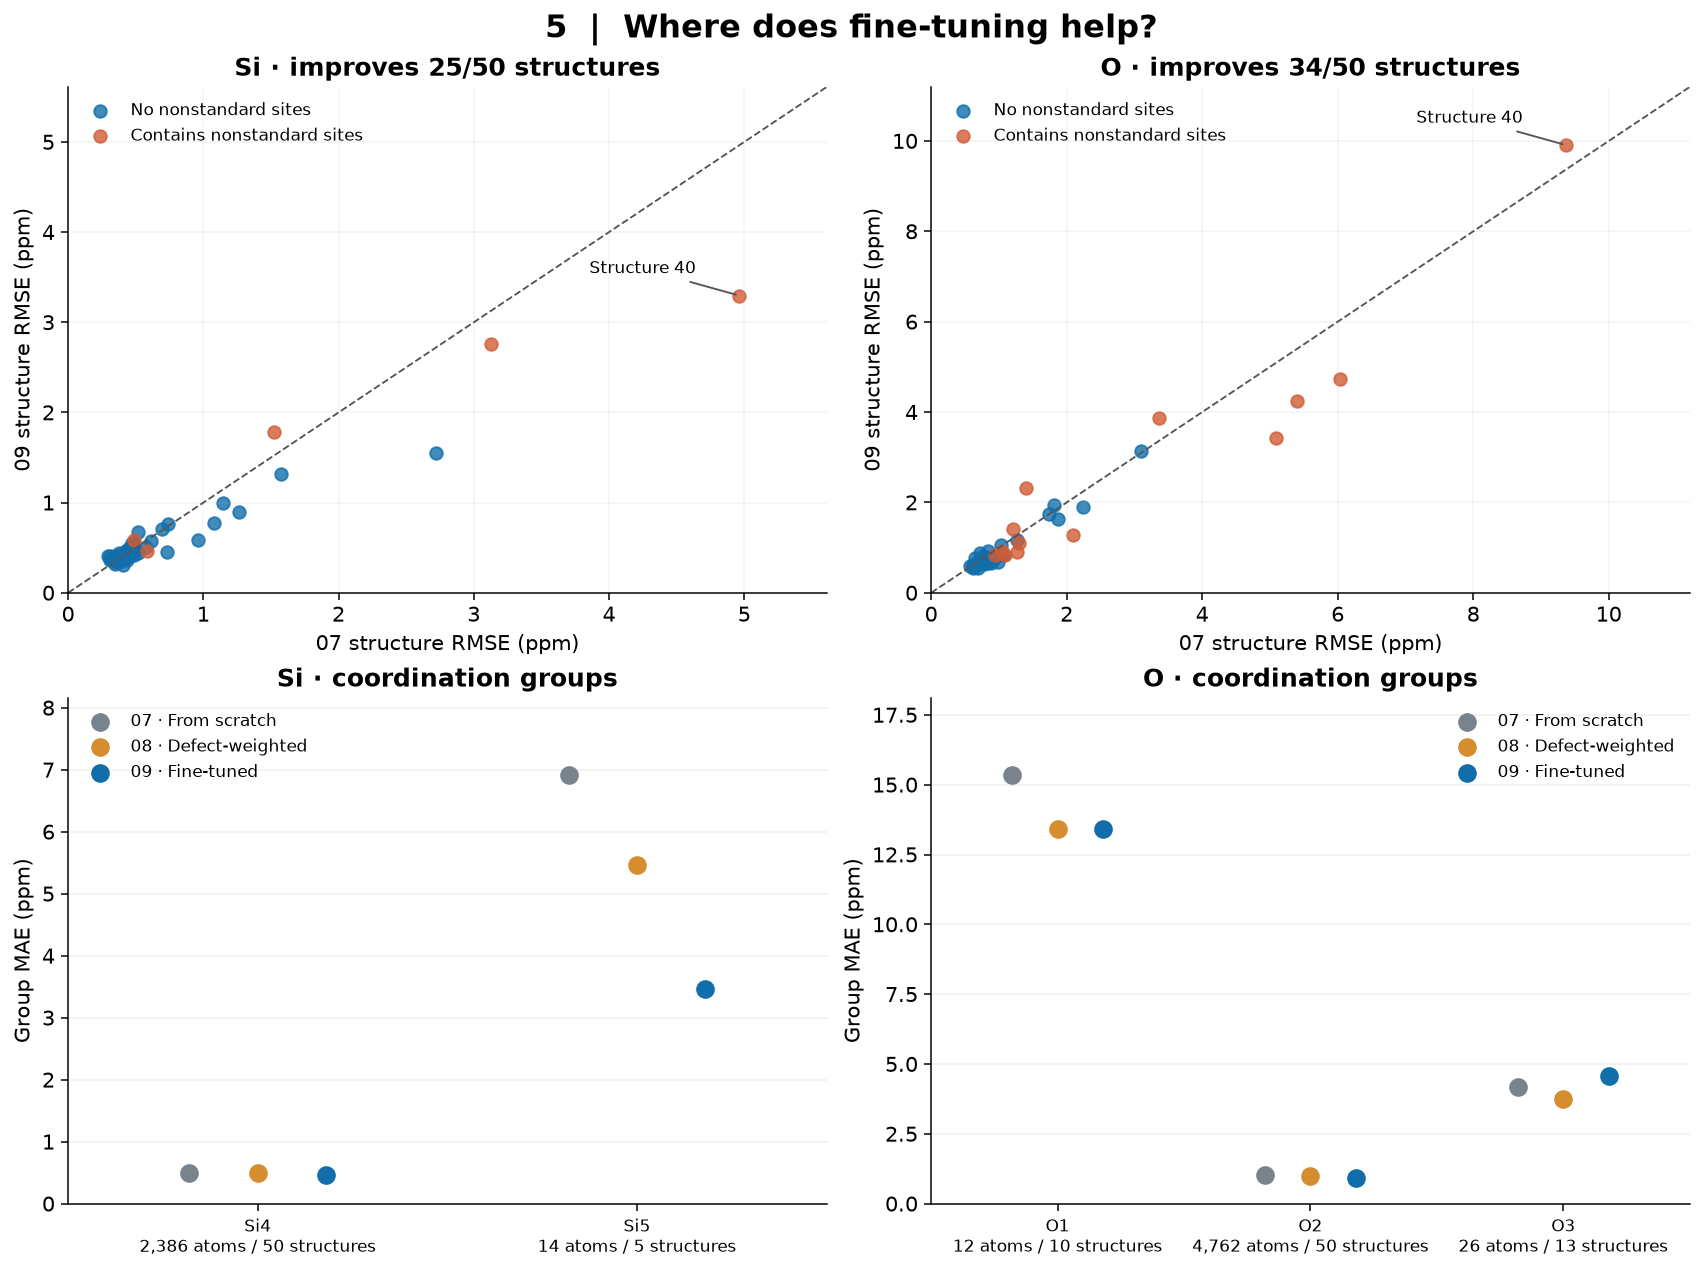

,run,category,N,structures,MAE,RMSE,max
0,07,O1,12,10,15.347,20.868,42.041
1,07,O2,4762,50,1.018,1.944,27.891
2,07,O3,26,13,4.163,5.416,12.163
3,07,Si4,2386,50,0.500,0.884,14.036
4,07,Si5,14,5,6.915,8.549,16.139
5,08,O1,12,10,13.409,17.611,34.124
6,08,O2,4762,50,1.003,1.933,29.252
7,08,O3,26,13,3.751,5.001,11.630
8,08,Si4,2386,50,0.501,0.849,9.397
9,08,Si5,14,5,5.464,6.878,12.946


In [8]:
fig,axes=plt.subplots(2,2,figsize=(12.5,9.3),layout='constrained')
structure_comparison=[]
for col,el in enumerate(ELEMENTS):
 ax=axes[0,col]
 p=structure_metrics.query('element==@el').pivot(index='structure',columns='run',values='RMSE')
 good=int((p['09']<p['07']).sum());structure_comparison.append({'element':el,'structures_improved':good,'total':len(p)})
 defect_structures=set(geometry.query('element==@el and defect').structure)
 for flag,color,label in [(False,COLORS['09'],'No nonstandard sites'),(True,'#D05C35','Contains nonstandard sites')]:
  mask=p.index.isin(defect_structures)==flag
  ax.scatter(p.loc[mask,'07'],p.loc[mask,'09'],c=color,s=45,alpha=.8,label=label)
 limit=max(p['07'].max(),p['09'].max())*1.13
 ax.plot([0,limit],[0,limit],'--',color='#555555',lw=1)
 idx=p['07'].idxmax();ax.annotate(f'Structure {idx}',(p.loc[idx,'07'],p.loc[idx,'09']),xytext=(-80,12),textcoords='offset points',fontsize=9,arrowprops={'arrowstyle':'-','color':'#555555'})
 ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='07 structure RMSE (ppm)',ylabel='09 structure RMSE (ppm)',title=f'{el} · improves {good}/50 structures')
 ax.legend(fontsize=9,loc='upper left');ax.grid(alpha=.15)
 ax=axes[1,col];cats=['Si4','Si5'] if el=='Si' else ['O1','O2','O3'];x=np.arange(len(cats))
 for j,run in enumerate(RUNS):
  g=coord_metrics.query('run==@run').set_index('category').loc[cats]
  ax.scatter(x+(j-1)*.18,g.MAE,s=80,color=COLORS[run],label=LABELS[run],zorder=3)
 g=coord_metrics.query('run=="09"').set_index('category').loc[cats]
 ax.set(xticks=x,xticklabels=[f'{cat}\n{int(g.loc[cat,"N"]):,} atoms / {int(g.loc[cat,"structures"])} structures' for cat in cats],ylabel='Group MAE (ppm)',ylim=(0,g.MAE.max()*1.15 if g.MAE.max()>coord_metrics.query('element==@el').MAE.max() else coord_metrics.query('element==@el').MAE.max()*1.18),title=f'{el} · coordination groups',xlim=(-.5,len(cats)-.5))
 ax.tick_params(axis='x',labelsize=9);ax.grid(axis='y',alpha=.2);ax.legend(fontsize=9,loc='upper left' if el=='Si' else 'upper right')
fig.suptitle('5  |  Where does fine-tuning help?',fontsize=17,fontweight='bold')
finish(fig,'05-structures-and-environments')
structure_comparison=pd.DataFrame(structure_comparison)
structure_comparison.to_csv(ARTIFACTS/'structure-improvement.csv',index=False)
display(coord_metrics[['run','category','N','structures','MAE','RMSE','max']].round(3))

# Contribution of structure 40 to the total 07→09 squared-error reduction.
sse_contributions=[]
for el in ELEMENTS:
    p=structure_metrics.query('element==@el').pivot(index='structure',columns='run',values='RMSE')
    n=structure_metrics.query('run=="07" and element==@el').set_index('structure').N
    reduction=n*(p['07']**2-p['09']**2)
    sse_contributions.append({'element':el,'structure40_share_of_SSE_reduction_pct':100*reduction.loc[40]/reduction.sum()})
pd.DataFrame(sse_contributions).to_csv(ARTIFACTS/'structure40-contribution.csv',index=False)


**Takeaway:** 09 improves structure RMSE in **25/50 Si cohorts** and **34/50 O cohorts**. Si's aggregate gain is concentrated in difficult structures: structure 40 alone supplies **59.9% of the total Si squared-error reduction** versus 07 (structure RMSE **4.964 → 3.296 ppm**). In that same structure, O RMSE worsens **9.374 → 9.907 ppm**. Si5 MAE roughly halves (**6.915 → 3.456 ppm**), but this rests on only **14 atoms in five structures**. O3 MAE worsens (**4.163 → 4.574 ppm**). The result supports improvement for this recipe, not a universal cure for unusual coordination.


## Takeaways and limits

The statements below are calculated from the plotted data. All five figures and supporting tables are saved alongside the notebook. Subgroup counts are checked at 2.1, 2.2 and 2.3 Å as a sensitivity diagnostic; they do not enter the model or change any reported overall error.


In [9]:
lines=[]
for el in ELEMENTS:
 c=comparisons.query('baseline=="07" and element==@el').set_index('metric')
 m=metrics.query('run=="09" and element==@el').iloc[0]
 old=metrics.query('run=="07" and element==@el').iloc[0]
 s=structure_comparison.query('element==@el').iloc[0]
 w=spectral.query('element==@el').set_index('run')
 t=concentration.query('run=="09" and element==@el').iloc[0]
 lines.append(f'**{el}:** fine-tuning changes MAE from **{old.MAE:.3f} to {m.MAE:.3f} ppm** and RMSE from **{old.RMSE:.3f} to {m.RMSE:.3f} ppm** ({c.loc["MAE","reduction_pct"]:.1f}% and {c.loc["RMSE","reduction_pct"]:.1f}% reductions). It improves structure RMSE in **{int(s.structures_improved)}/50 structures**. Distribution W₁ changes from **{w.loc["07","W1_ppm"]:.3f} to {w.loc["09","W1_ppm"]:.3f} ppm**. There are still **{int(m.above10)} atoms above 10 ppm error**, with a maximum of **{m["max"]:.2f} ppm**; the worst 1% contribute **{t.top1pct_SSE_pct:.1f}%** of squared error.')
for line in lines:display(Markdown(line))
display(Markdown('**Interpretation:** a lower validation error supports this fine-tuning recipe on the present split. It does not by itself isolate the benefit of pretraining: 09 also uses a lower learning rate than 07, and there is only one seed per recipe. A clean attribution experiment would compare pretrained and randomly initialised versions using the same learning rate, training schedule and multiple seeds. Distribution agreement and atom-wise agreement should both guide the NMR decision; rare-site maxima alone do not describe the quality of the bulk distribution.'))
sensitivity=[]
for cutoff in [2.1,2.2,2.3]:
 for el in ELEMENTS:
  g=sites.query('run=="09" and element==@el');bad=g[f'CN_{cutoff:.1f}'].ne(4 if el=='Si' else 2)
  sensitivity.append({'cutoff_A':cutoff,'element':el,'nonstandard_sites':int(bad.sum()),'nonstandard_RMSE':np.sqrt(np.mean(g.loc[bad,'error']**2)) if bad.any() else np.nan})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity.round(3));sensitivity.to_csv(ARTIFACTS/'coordination-cutoff-sensitivity.csv',index=False)
manifest={'target':'trace(ms)/3 absolute isotropic shielding','units':'ppm','split':'validation only','structures':len(frames),'atoms':len(geometry),'data_sha256':sha256(valid_path),'runs':provenance.to_dict('records'),'versions':{p:version(p) for p in ['torch','graph-pes','e3nn','numpy','ase','scipy','matplotlib']},'helpers':{p.name:sha256(p) for p in (PROJECT/'nmr_helpers').glob('*.py')},'bootstrap':{'unit':'structure','paired':True,'resamples':4000,'seed':42},'coordination_cutoff_A':2.2,'illustrative_gaussian_sigma_ppm':SIGMA,'device':'CPU','torch_threads':2,'model_inputs':'species, positions, cell and periodicity; no target properties','test_set_accessed':False,'figures':sorted(p.name for p in ARTIFACTS.glob('*.png'))}
assert len(manifest['figures'])==5
(ARTIFACTS/'manifest.json').write_text(json.dumps(manifest,indent=2))
(ARTIFACTS/'takeaways.txt').write_text('\n\n'.join(lines))
print('Reproducibility manifest saved. Exactly five figures; 50 validation structures; no test-set access.')


Reproducibility manifest saved. Exactly five figures; 50 validation structures; no test-set access.


**Si:** fine-tuning changes MAE from **0.538 to 0.486 ppm** and RMSE from **1.097 to 0.862 ppm** (9.7% and 21.4% reductions). It improves structure RMSE in **25/50 structures**. Distribution W₁ changes from **0.117 to 0.119 ppm**. There are still **0 atoms above 10 ppm error**, with a maximum of **9.87 ppm**; the worst 1% contribute **47.8%** of squared error.

**O:** fine-tuning changes MAE from **1.071 to 0.957 ppm** and RMSE from **2.235 to 2.093 ppm** (10.7% and 6.4% reductions). It improves structure RMSE in **34/50 structures**. Distribution W₁ changes from **0.199 to 0.183 ppm**. There are still **42 atoms above 10 ppm error**, with a maximum of **45.82 ppm**; the worst 1% contribute **61.6%** of squared error.

**Interpretation:** a lower validation error supports this fine-tuning recipe on the present split. It does not by itself isolate the benefit of pretraining: 09 also uses a lower learning rate than 07, and there is only one seed per recipe. A clean attribution experiment would compare pretrained and randomly initialised versions using the same learning rate, training schedule and multiple seeds. Distribution agreement and atom-wise agreement should both guide the NMR decision; rare-site maxima alone do not describe the quality of the bulk distribution.

,cutoff_A,element,nonstandard_sites,nonstandard_RMSE
0,2.1,Si,16,3.777
1,2.1,O,36,12.317
2,2.2,Si,14,4.198
3,2.2,O,38,11.806
4,2.3,Si,17,4.391
5,2.3,O,41,11.613
